# ЭКЗАМЕНАЦИОННАЯ ЗАДАЧА №2: Оценка экономической эффективности внедрения облачной CRM

**Дата:** 2026-10-22
**Студент:** Ижедерова Виктория Денисовна
**Группа:** ПИ-4.1

**Цель:** Оценить экономическую эффективность внедрения облачной CRM-системы для отдела продаж компании «ТехноПром» с применением методов NPV, ROI, Payback Period и анализом нематериальных эффектов в контексте парадокса производительности Солоу.

In [2]:
# Импорт библиотек
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# Исходные данные
n_managers = 15
salary_month = 120_000
routine_share = 0.30
crm_time_saving = 0.20
sales_growth = 0.08
annual_revenue = 72_000_000
license_per_user_year = 24_000
adaptation_months = 1
horizon = 3
discount_rate = 0.12
tax_rate = 0.20

print(" Исходные данные загружены")

 Исходные данные загружены


## 1. ПРЯМОЙ ЭФФЕКТ ОТ ВНЕДРЕНИЯ CRM
### 1.1 Экономия на заработной плате
### 1.2 Дополнительный доход от роста продаж

In [4]:
# 1.1 Экономия на зарплате
annual_payroll = n_managers * salary_month * 12
time_saving_share = routine_share * crm_time_saving
salary_saving = time_saving_share * annual_payroll

print("1.1. Экономия на заработной плате")
print("-" * 55)
print(f"Годовой ФОТ: {annual_payroll:,.0f} руб.")
print(f"Доля сэкономленного времени: {time_saving_share*100:.1f}%")
print(f"Экономия на зарплате: {salary_saving:,.0f} руб./год")

# 1.2 Дополнительный доход от роста продаж
extra_revenue = sales_growth * annual_revenue
print("\n1.2. Дополнительный доход от роста продаж")
print("-" * 55)
print(f"Рост продаж: {sales_growth*100:.0f}%")
print(f"Дополнительный доход: {extra_revenue:,.0f} руб./год")

# Итого прямой эффект
total_effect = salary_saving + extra_revenue
print(f"\nИТОГО годовой прямой эффект: {total_effect:,.0f} руб.")

1.1. Экономия на заработной плате
-------------------------------------------------------
Годовой ФОТ: 21,600,000 руб.
Доля сэкономленного времени: 6.0%
Экономия на зарплате: 1,296,000 руб./год

1.2. Дополнительный доход от роста продаж
-------------------------------------------------------
Рост продаж: 8%
Дополнительный доход: 5,760,000 руб./год

ИТОГО годовой прямой эффект: 7,056,000 руб.


## 2. ЗАТРАТЫ НА ВНЕДРЕНИЕ
### 2.1 Стоимость лицензий за 3 года
### 2.2 Потери от снижения производительности в период адаптации

In [6]:
# 2.1 Лицензии
license_year = n_managers * license_per_user_year
license_total = license_year * horizon

print("2.1. Стоимость лицензий")
print("-" * 55)
print(f"Лицензии в год: {license_year:,.0f} руб.")
print(f"Лицензии за 3 года: {license_total:,.0f} руб.")

# 2.2 Потери от адаптации
adaptation_loss = (annual_payroll / 12) * adaptation_months
print("\n2.2. Потери от адаптации (1 месяц)")
print("-" * 55)
print(f"Потери в первый месяц: {adaptation_loss:,.0f} руб.")

total_costs = license_total + adaptation_loss
print(f"\nИТОГО затрат за 3 года: {total_costs:,.0f} руб.")

2.1. Стоимость лицензий
-------------------------------------------------------
Лицензии в год: 360,000 руб.
Лицензии за 3 года: 1,080,000 руб.

2.2. Потери от адаптации (1 месяц)
-------------------------------------------------------
Потери в первый месяц: 1,800,000 руб.

ИТОГО затрат за 3 года: 2,880,000 руб.


## 3. ФИНАНСОВЫЕ ПОКАЗАТЕЛИ ЭФФЕКТИВНОСТИ
### 3.1 Прирост чистой прибыли по годам (с учётом налога)
### 3.2 NPV проекта (r = 12%)
### 3.3 Простой срок окупаемости
### 3.4 ROI проекта

In [8]:
# 3.1 Чистая прибыль по годам
years = np.arange(1, horizon + 1)
effects = np.full(horizon, total_effect)
licenses = np.full(horizon, license_year)
adaptation = np.zeros(horizon)
adaptation[0] = adaptation_loss

ebt = effects - licenses - adaptation
tax = ebt * tax_rate
net_profit = ebt - tax

df = pd.DataFrame({
    'Год': years,
    'Эффект': effects,
    'Лицензии': licenses,
    'Адаптация': adaptation,
    'EBT': ebt,
    'Налог': tax,
    'Чистая прибыль': net_profit
})

print("3.1. Прирост чистой прибыли по годам")
print("=" * 75)
print(df.to_string(index=False))
print("=" * 75)

# 3.2 NPV
npv = np.sum(net_profit / (1 + discount_rate) ** years)
print(f"\n3.2. NPV проекта (r={discount_rate*100:.0f}%): {npv:,.0f} руб.")
print("NPV > 0 → проект экономически эффективен")

# 3.3 Payback
cumulative = np.cumsum(net_profit)
payback_years = adaptation_loss / net_profit[0]
print(f"\n3.3. Простой срок окупаемости: {payback_years:.2f} года "
      f"(≈ {payback_years*12:.1f} месяцев)")

# 3.4 ROI
roi = (np.sum(net_profit) - total_costs) / total_costs * 100
print(f"\n3.4. ROI за 3 года: {roi:.0f}%")
print(f"     ROI в год (средний): {roi/horizon:.0f}%")

3.1. Прирост чистой прибыли по годам
 Год    Эффект  Лицензии  Адаптация       EBT     Налог  Чистая прибыль
   1 7056000.0    360000  1800000.0 4896000.0  979200.0       3916800.0
   2 7056000.0    360000        0.0 6696000.0 1339200.0       5356800.0
   3 7056000.0    360000        0.0 6696000.0 1339200.0       5356800.0

3.2. NPV проекта (r=12%): 11,580,415 руб.
NPV > 0 → проект экономически эффективен

3.3. Простой срок окупаемости: 0.46 года (≈ 5.5 месяцев)

3.4. ROI за 3 года: 408%
     ROI в год (средний): 136%


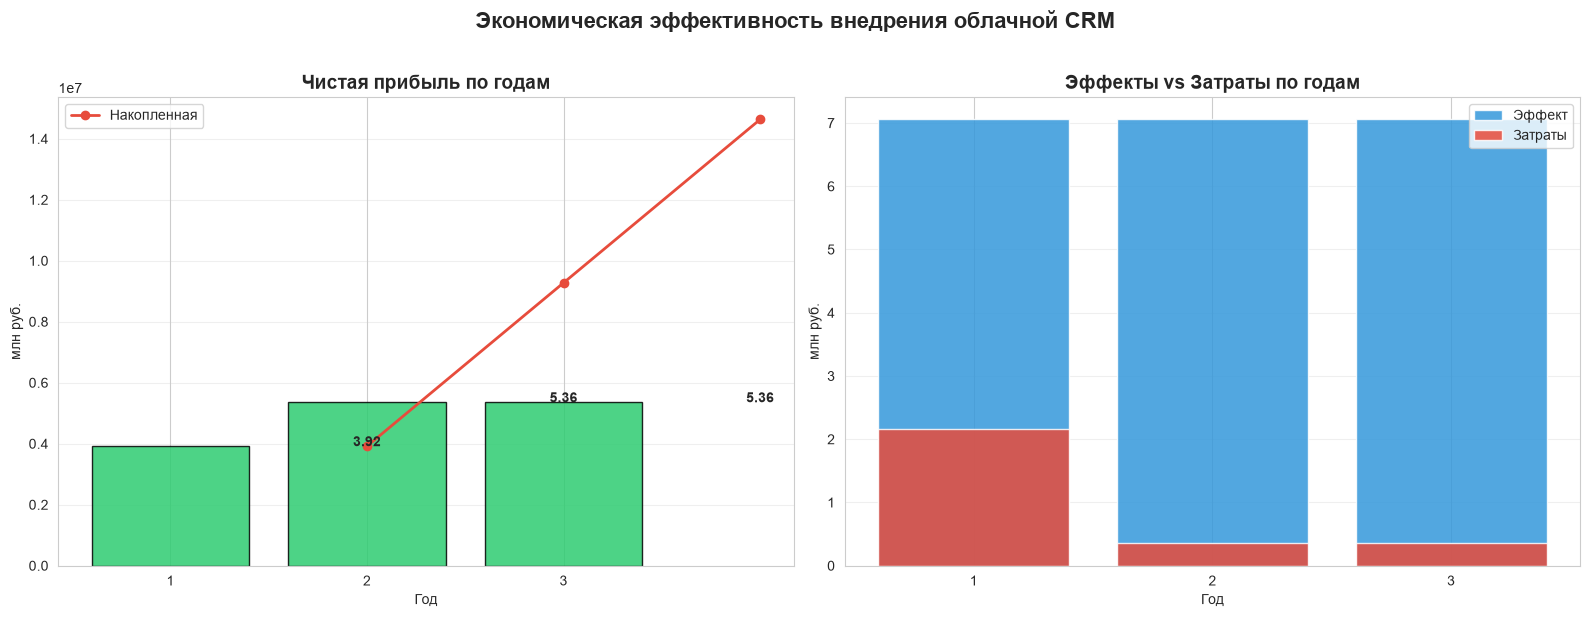

Графики построены


In [9]:
# Визуализация денежных потоков
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].bar(years.astype(str), net_profit, color='#2ECC71', alpha=0.85, edgecolor='black')
axes[0].plot(years, np.cumsum(net_profit), 'o-', color='#E74C3C', linewidth=2, label='Накопленная')
axes[0].set_title('Чистая прибыль по годам', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Год'); axes[0].set_ylabel('млн руб.')
axes[0].legend(); axes[0].grid(axis='y', alpha=0.3)
for i, v in enumerate(net_profit):
    axes[0].text(years[i], v + 0.1, f'{v/1e6:.2f}', ha='center', fontweight='bold')

axes[1].bar(years.astype(str), effects/1e6, color='#3498DB', alpha=0.85, label='Эффект')
axes[1].bar(years.astype(str), (licenses+adaptation)/1e6, color='#E74C3C', alpha=0.85, label='Затраты')
axes[1].set_title('Эффекты vs Затраты по годам', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Год'); axes[1].set_ylabel('млн руб.')
axes[1].legend(); axes[1].grid(axis='y', alpha=0.3)

plt.suptitle('Экономическая эффективность внедрения облачной CRM', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout(); plt.show()
print("Графики построены")

## 4. НЕМАТЕРИАЛЬНЫЕ ЭФФЕКТЫ И ПАРАДОКС СОЛОУ

### 4.1 Нематериальные выгоды CRM
- **Снижение информационной асимметрии** (Акерлоф): единая база клиентов уравнивает менеджеров и снижает риск «рынка лимонов».
- **Снижение морального риска** (скрытые действия): история взаимодействия с клиентом сохраняется, клиент не «теряется» при увольнении менеджера.
- **Рост социального капитала ИТ-капитала**: доверие клиентов, репутация, качество данных.
- **Эффект масштаба**: каждая копия данных о клиенте стоит ≈ 0 (неконкурентность информации).

### 4.2 Парадокс производительности Солоу
Расчётный эффект (7,056 млн/год) может быть **завышен** из-за:
1. **Измерительного лага** — рост продаж сложно однозначно атрибутировать CRM.
2. **Технологического лага** — реальное освоение системы дольше 1 месяца.
3. **Эффекта перераспределения** — CRM может перераспределять продажи между менеджерами, а не создавать новые.
4. **Иллюзии роста** — 8% могут быть следствием сезонности или маркетинга.

### 4.3 Рекомендации
- Провести A/B-тест (отдел с CRM vs без) для валидации эффекта.
- Внедрить трекер KPI и пересматривать NPV ежеквартально.
- Инвестировать в обучение (человеческий капитал) для сокращения технологического лага.
- Учитывать нематериальные эффекты при принятии решения — они не входят в NPV, но повышают реальную ценность.

---
**Вывод:** NPV = 11,58 млн руб. > 0, ROI ≈ 408%, окупаемость ≈ 5,5 мес. → **проект внедрения CRM экономически эффективен**, но фактический результат следует верифицировать с учётом парадокса Солоу.